# WeVisOne-VL-4B：停车场官方原生任务独立诊断

本 Notebook 不参与 Xiaomi-Lens-0 / Qwen3.5-4B / WeVisOne-VL-4B 的**同提示词**直接比较。这里使用腾讯官方 `predict(image, task=..., query=...)`，其内部会按照不同 `task` 自动构建专用提示词。

- **测试一**：右侧最下方红车——`referring`（框）+ `segmentation`（框和 Mask）。
- **测试二**：全部蓝车——`detection`（框）+ `segmentation`（框和 Mask）。
- **测试三**：全图最下方蓝车——`referring` + `segmentation`，再与“全部蓝车框排序”作**算法辅助诊断**。
- **测试四**：定位 A、执行左移一列且上移一行定位 B——对 A/B 分别执行 `referring` + `segmentation`，并叠加显示。

**注意**：`referring` 的返回不保证具有 Mask；`segmentation` 也只有输出 `<OBJ>` 且解码成功才有真实 Mask。不会把 BBox 冒充 Mask。测试三排序属于程序化后处理，**不能计为模型独立完成复杂空间推理**；测试四的两个查询是分步诊断而非原题一次性推理。全程采用无长标签遮挡的可视化。 


## 0. 初始化

选择已有 `wevisone-vl` 解释器。假如当前 Jupyter 内核已经加载了 `WeVisOneVL`，下面会复用当前模型，不重复占用显存；否则自动加载本地完整权重，未找到时使用 `tencent/WeVisOne-VL-4B` 模型 ID。


/home/20261024_1/.local/share/mamba/envs/wevisone-vl/lib/python3.12/site-packages/supervision/annotators/core.py:12: UserWarning: OpenCV (`opencv-python`) is not installed; supervision is using its pure NumPy fallback backend instead. Some operations may be slower or behave slightly differently. Install `opencv-python` for full performance and compatibility.
  from supervision import _cv2 as cv2
/home/20261024_1/.local/share/mamba/envs/wevisone-vl/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 714/714 [00:00<00:00, 10675.50it/s]


新加载模型： tencent/WeVisOne-VL-4B
图片1： (451, 300) 图片2： (1313, 1080)


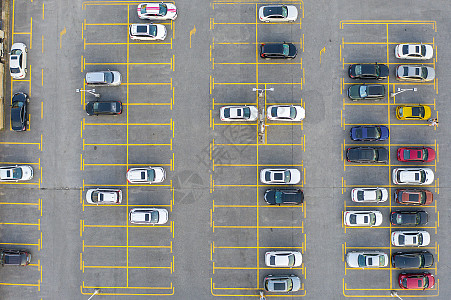

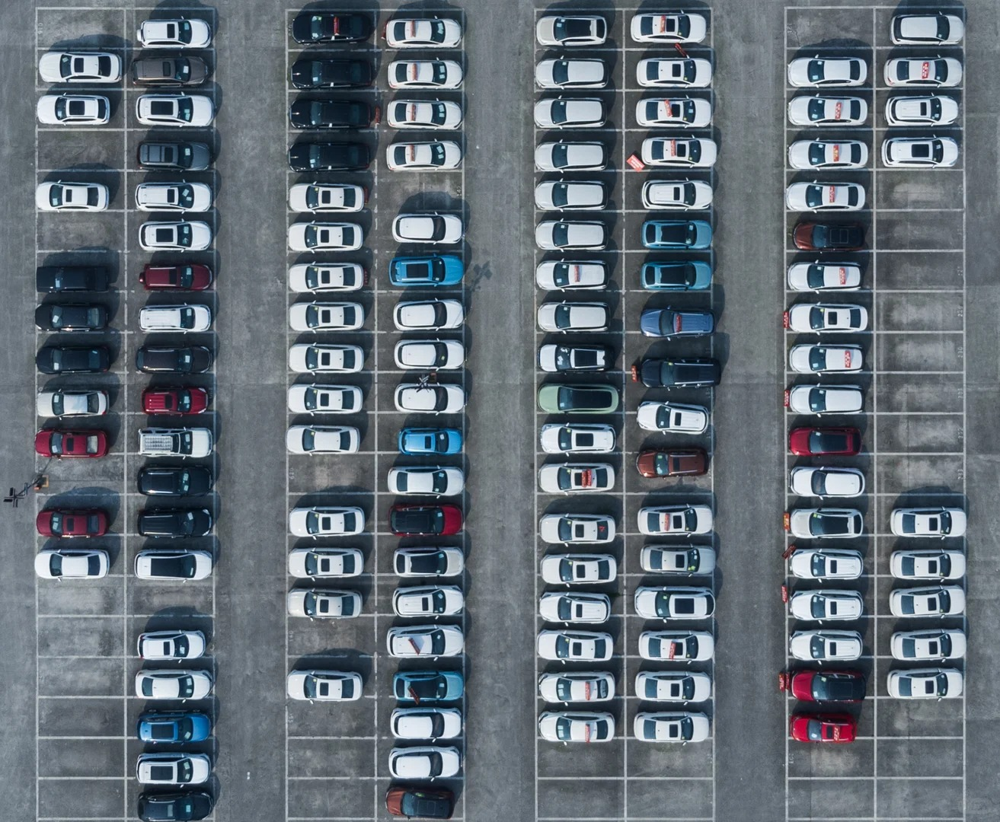

In [1]:
import sys
import re
import json
import time
from pathlib import Path

import numpy as np
import torch
from PIL import Image, ImageDraw
from IPython.display import display

ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / "datasets/几何简单测试").is_dir()),
    None,
)
assert ROOT is not None, "未找到 VLM-test 根目录，请在该项目下打开 Notebook"

TENCENT_ROOT = ROOT / "models/WeVisOne-VL"
if TENCENT_ROOT.is_dir() and str(TENCENT_ROOT) not in sys.path:
    sys.path.insert(0, str(TENCENT_ROOT))

from wevisone_vl import WeVisOneVL
from wevisone_vl.visualization import parse_predictions

if not isinstance(globals().get("model", None), WeVisOneVL):
    local = TENCENT_ROOT / "checkpoints/WeVisOne-VL-4B"
    model_path = (str(local) if (local / "config.json").is_file()
                  and (local / "mask_decoder.pt").is_file()
                  else "tencent/WeVisOne-VL-4B")
    model = WeVisOneVL(
        model_path,
        backend="transformers",
        device="auto",
        dtype="bfloat16",
        min_pixels=224 * 224,
        max_pixels=2048 * 2048,
        attention_implementation="sdpa",
    )
    print("新加载模型：", model_path)
else:
    print("复用当前内核中的 WeVisOneVL 模型")

DATA_DIR = ROOT / "datasets/几何简单测试"
img1 = Image.open(DATA_DIR / "停车场图1.png").convert("RGB")
img2 = Image.open(DATA_DIR / "停车场图2.jpg").convert("RGB")
print("图片1：", img1.size, "图片2：", img2.size)
display(img1, img2)


## 1. 原生推理 + 干净可视化函数

只绘制**彩色细框、短编号和半透明 Mask**，完整结构化回答打印在图下方；不使用会覆盖图片的官方长文本标签。结果可自动保存在项目目录 `evaluation/几何理解简单测试/WeVisOne原生诊断输出/` 下。


In [2]:
SAVE_OUTPUTS = True
OUT_DIR = ROOT / "evaluation/几何理解简单测试/WeVisOne原生诊断输出"
PALETTE = [
    (255, 77, 82), (36, 220, 108), (40, 157, 250),
    (255, 184, 48), (177, 97, 255), (37, 218, 211),
]

def _iou(b1, b2):
    xa, ya = max(b1[0], b2[0]), max(b1[1], b2[1])
    xb, yb = min(b1[2], b2[2]), min(b1[3], b2[3])
    inter = max(0, xb-xa) * max(0, yb-ya)
    area1 = max(0,b1[2]-b1[0]) * max(0,b1[3]-b1[1])
    area2 = max(0,b2[2]-b2[0]) * max(0,b2[3]-b2[1])
    return inter / max(1e-8, area1+area2-inter)

def _unique_boxes(boxes, threshold=0.98):
    out = []
    for b in boxes:
        b = [float(x) for x in b]
        if not (b[0] < b[2] and b[1] < b[3]):
            continue
        if not any(_iou(b, old) >= threshold for old in out):
            out.append(b)
    return out

def get_native_boxes(image, result):
    """返回像素坐标 xyxy；优先使用与真实 Mask 对应的官方 boxes。"""
    w, h = image.size
    if result.masks and result.boxes:
        boxes = [[b[0]*w, b[1]*h, b[2]*w, b[3]*h]
                 for b in result.boxes]
        return _unique_boxes(boxes)
    parsed = parse_predictions(result.response or "", w, h)
    boxes = [a["coords"] for anns in parsed.values()
             for a in anns if a.get("type") == "box"]
    if not boxes:
        # 兼容只有 <box><x1><y1><x2><y2></box> 的回复。
        for m in re.finditer(r"<box>(.*?)(?:</box>|$)",
                             result.response or "", flags=re.S|re.I):
            values = [int(v) for v in re.findall(r"<(\d{1,4})>", m.group(1))]
            for k in range(0, len(values)-3, 4):
                x1,y1,x2,y2 = values[k:k+4]
                if 0 <= x1 < x2 <= 1000 and 0 <= y1 < y2 <= 1000:
                    boxes.append([x1*w/1000,y1*h/1000,x2*w/1000,y2*h/1000])
    return _unique_boxes(boxes)

def native_overlay(image, result, boxes=None, label_prefix="", opacity=0.42):
    w,h = image.size
    boxes = get_native_boxes(image,result) if boxes is None else boxes
    scene = np.asarray(image.convert("RGB"), dtype=np.float32).copy()
    for i, mask in enumerate(result.masks):
        arr = np.asarray(mask, dtype=np.float32)
        if arr.shape != (h,w):
            arr = np.asarray(Image.fromarray(arr, mode="F").resize(
                (w,h), Image.Resampling.BILINEAR), dtype=np.float32)
        strength = (np.clip(arr,0,1)*opacity)[...,None]
        tint = np.asarray(PALETTE[i%len(PALETTE)], dtype=np.float32)
        scene = scene*(1-strength) + tint*strength
    canvas = Image.fromarray(np.uint8(np.clip(scene,0,255)))
    draw = ImageDraw.Draw(canvas)
    lw = max(2, int(round(w/450)))
    for i,b in enumerate(boxes):
        x1,y1,x2,y2 = [int(round(x)) for x in b]
        color = PALETTE[i%len(PALETTE)]
        draw.rectangle((x1,y1,x2,y2), outline=color, width=lw)
        tag = f"{label_prefix}{i+1}" if label_prefix else str(i+1)
        # 极小的编号，不用长英文描述覆盖图像。
        draw.text((x1+2,y1+2), tag, fill=color,
                  stroke_width=1, stroke_fill=(0,0,0))
    return canvas

def native_run(name, image, task, query, max_new_tokens=2048):
    print(f"\n========== {name} | {task} ==========")
    result = model.predict(
        image,
        task=task,
        query=query,
        temperature=0.0,
        max_new_tokens=max_new_tokens,
        decode_matting=True,
    )
    boxes = get_native_boxes(image, result)
    canvas = native_overlay(image, result, boxes)
    display(canvas)
    print("官方原生 query：", query)
    print("检测框数：",len(boxes),"| Mask 数：",len(result.masks),
          "| 推理耗时：",round(result.latency_s,2),"s")
    print("原始 response：\n", (result.response or "")[:2500])
    if len(result.masks) == 0:
        print("说明：本轮未产生可解码 Mask；没有把 BBox 假装成 Mask。")
    if SAVE_OUTPUTS:
        dst = OUT_DIR / name
        dst.mkdir(parents=True, exist_ok=True)
        canvas.save(dst / "overlay.png")
        (dst / "response.txt").write_text(result.response or "", encoding="utf-8")
        meta = {"task":task,"query":query,"bbox_xyxy_pixels":boxes,
                "num_masks":len(result.masks),"latency_s":result.latency_s}
        (dst / "meta.json").write_text(
            json.dumps(meta,ensure_ascii=False,indent=2), encoding="utf-8")
        for i,mask in enumerate(result.masks):
            m = np.asarray(mask,dtype=np.float32)
            Image.fromarray(np.uint8(np.clip(m,0,1)*255), mode="L").save(
                dst / f"mask_{i+1:02d}.png")
    return result


## 2. 测试一：单目标定位

目标与正式测试相同：**图片1最右侧停车列中最下方的红车**。`referring` 检查是否找对目标；`segmentation` 检查同一目标是否能生成 Mask。两次调用互相独立。



========== 01_red_referring | referring ==========


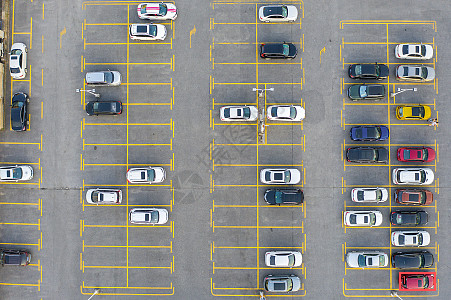

官方原生 query： the bottommost red car in the rightmost parking column
检测框数： 1 | Mask 数： 0 | 推理耗时： 1.57 s
原始 response：
 <ref>the bottommost red car in the rightmost parking column</ref><box><884><907><965><968></box>
说明：本轮未产生可解码 Mask；没有把 BBox 假装成 Mask。

========== 01_red_segmentation | segmentation ==========


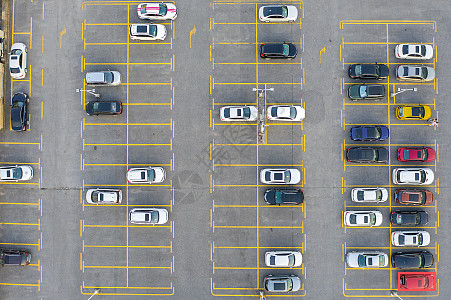

官方原生 query： the bottommost red car in the rightmost parking column
检测框数： 1 | Mask 数： 1 | 推理耗时： 1.02 s
原始 response：
 <ref>the bottommost red car in the rightmost parking column</ref><box><883><907><965><967><OBJ></box>


In [3]:
RED_QUERY = "the bottommost red car in the rightmost parking column"

t1_ref = native_run(
    "01_red_referring", img1,
    task="referring", query=RED_QUERY,
)
t1_seg = native_run(
    "01_red_segmentation", img1,
    task="segmentation", query=RED_QUERY,
)


## 3. 测试二：多目标定位

目标与正式测试相同：**图片2全部可见的蓝色车，不包含黑色或灰色车**。先用原生 `detection` 看检测框，再用 `segmentation` 看 Mask 和覆盖情况。框 / Mask 的数量与正确性需要结合原图人工检查。



========== 02_blue_detection | detection ==========


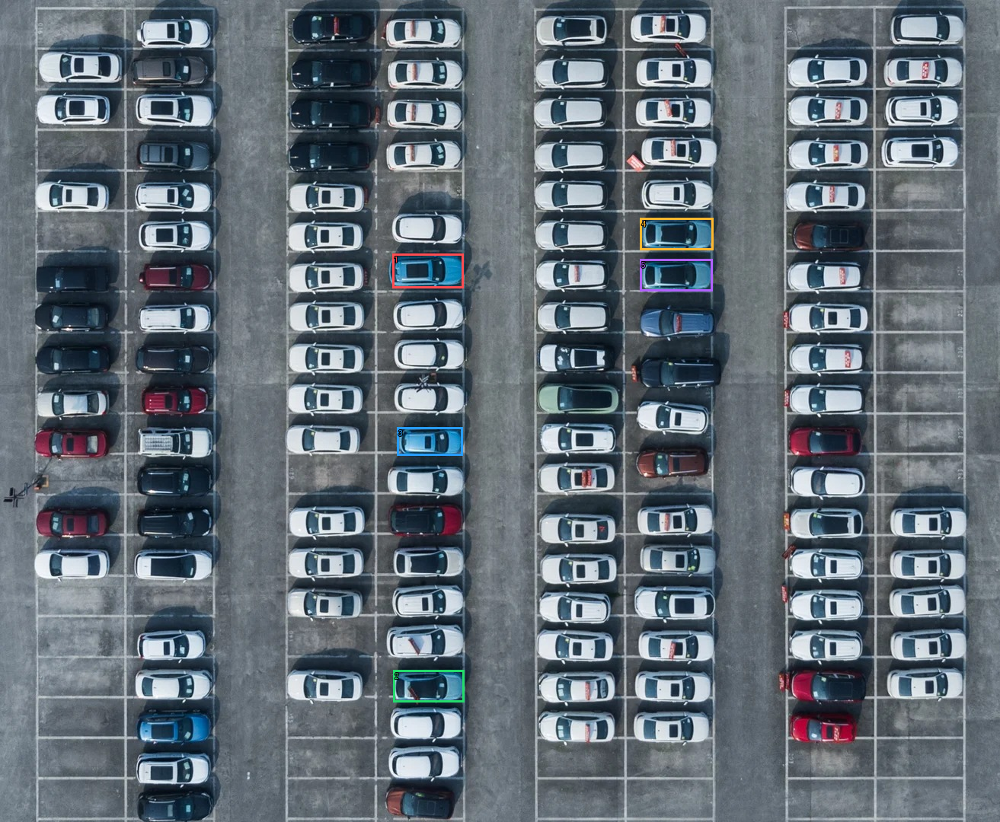

官方原生 query： visibly blue cars
检测框数： 5 | Mask 数： 0 | 推理耗时： 1.25 s
原始 response：
 <ref>visibly blue cars</ref><box><392><308><463><350>,<393><815><464><854>,<397><519><462><554>,<640><265><713><304>,<640><315><712><354></box>
说明：本轮未产生可解码 Mask；没有把 BBox 假装成 Mask。

========== 02_blue_segmentation | segmentation ==========


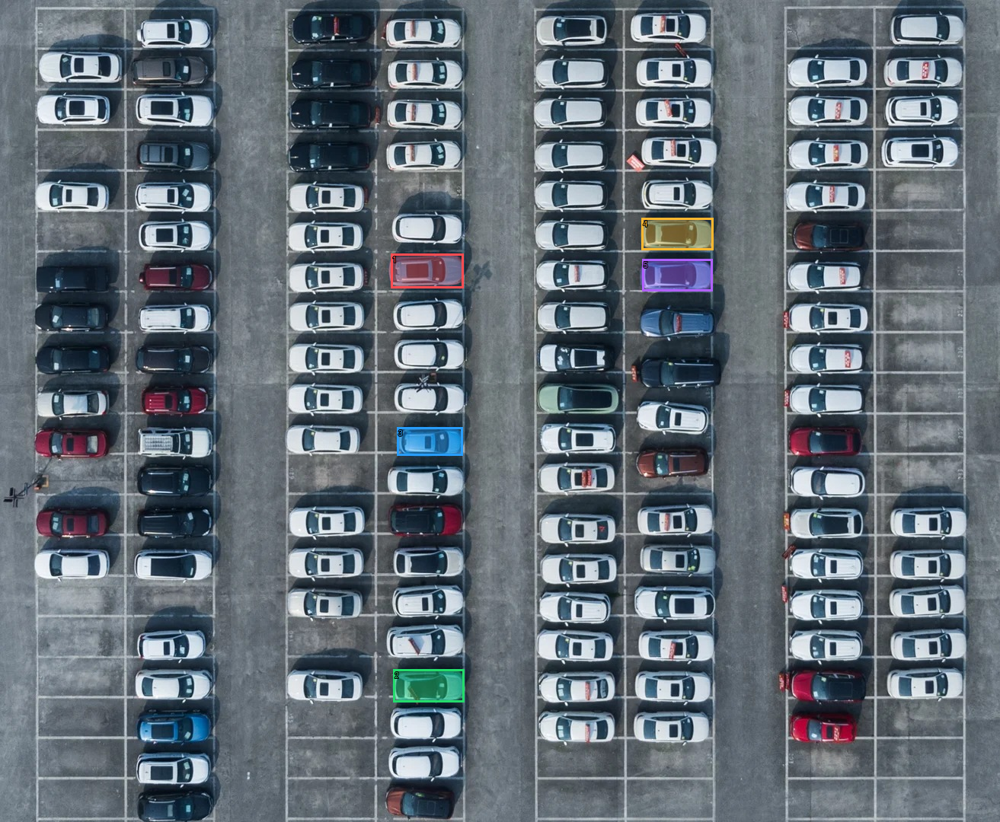

官方原生 query： visibly blue cars
检测框数： 5 | Mask 数： 5 | 推理耗时： 1.77 s
原始 response：
 <ref>visibly blue cars</ref><box><391><308><463><350><OBJ>,<393><814><464><854><OBJ>,<397><519><462><554><OBJ>,<641><265><713><304><OBJ>,<642><315><712><354><OBJ></box>


In [4]:
BLUE_QUERY = "visibly blue cars"

t2_det = native_run(
    "02_blue_detection", img2,
    task="detection", query=BLUE_QUERY,
)
t2_seg = native_run(
    "02_blue_segmentation", img2,
    task="segmentation", query=BLUE_QUERY,
)


## 4. 测试三：空间比较与极值定位

**路径 A：** 把“最下方蓝车”整体交给原生 `referring/segmentation`，观察其是否具备这类比较能力。

**路径 B：** 利用**测试二检测框**通过 Python 取纵向中心 `y_center` 最大的框。这是一个“检测 + 算法”的诊断基线，**不是腾讯模型独立完成空间推理**；如检测漏车，排序当然也可能错。



========== 03_lowest_blue_referring | referring ==========


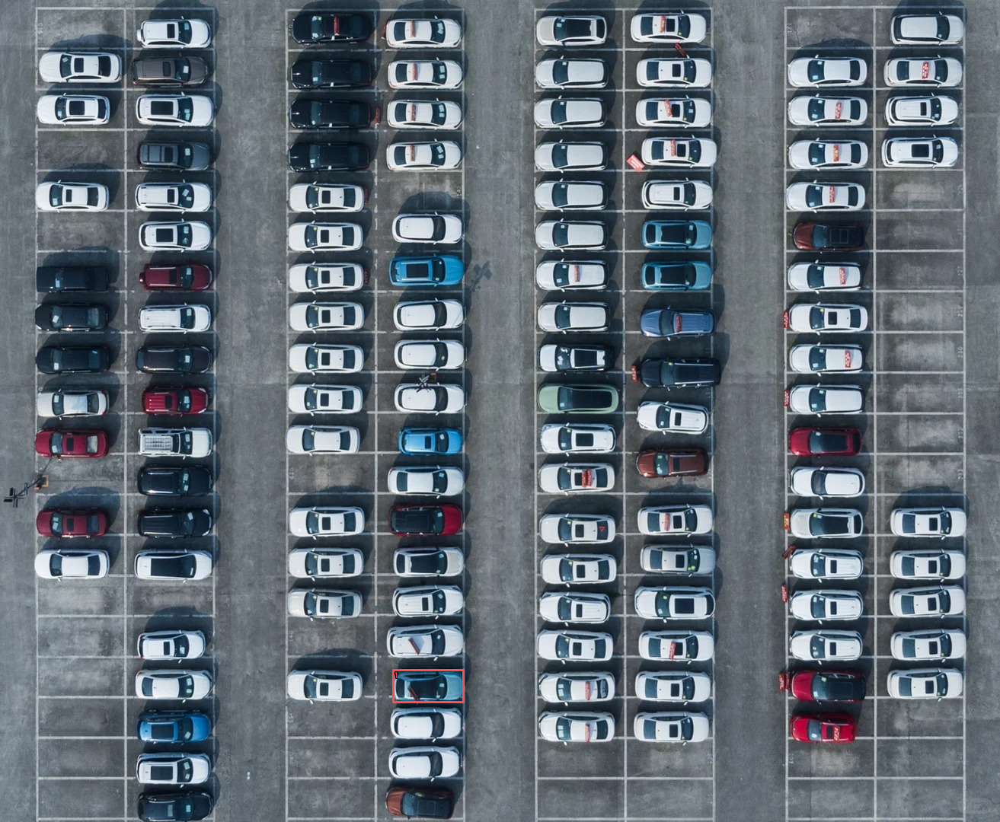

官方原生 query： the visibly blue car located lowest in the entire image (closest to the bottom edge of the image)
检测框数： 1 | Mask 数： 0 | 推理耗时： 1.16 s
原始 response：
 <ref>the visibly blue car located lowest in the entire image (closest to the bottom edge of the image)</ref><box><392><814><464><855></box>
说明：本轮未产生可解码 Mask；没有把 BBox 假装成 Mask。

========== 03_lowest_blue_segmentation | segmentation ==========


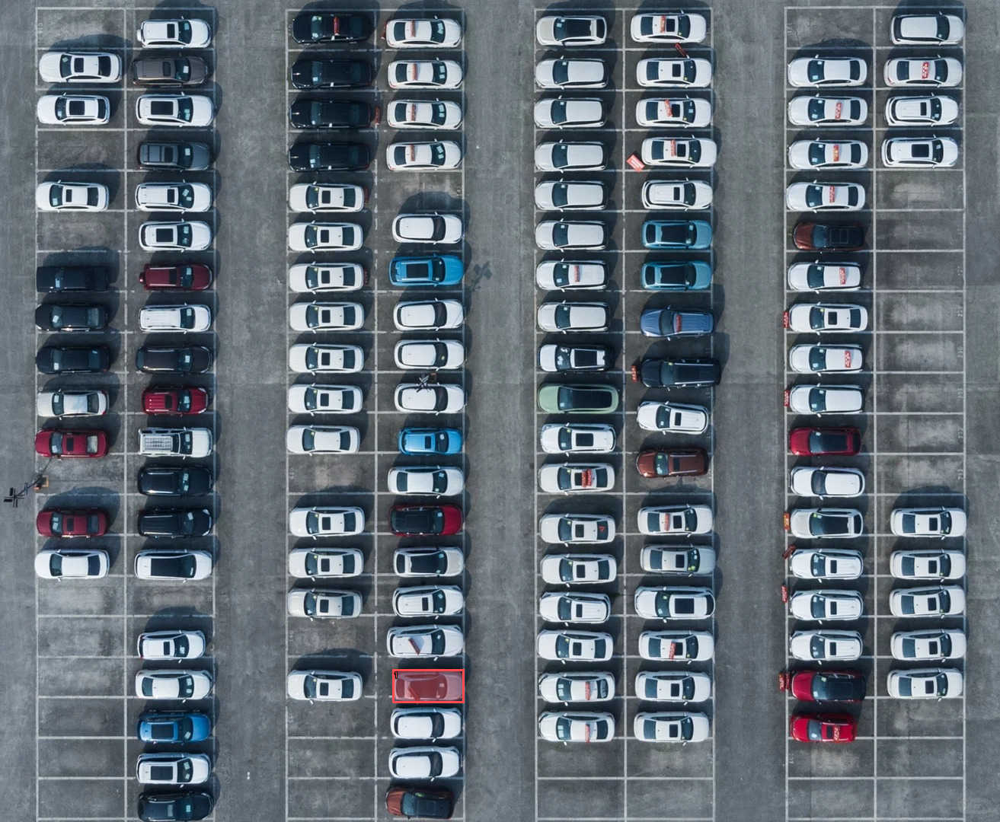

官方原生 query： the visibly blue car located lowest in the entire image (closest to the bottom edge of the image)
检测框数： 1 | Mask 数： 1 | 推理耗时： 1.41 s
原始 response：
 <ref>the visibly blue car located lowest in the entire image (closest to the bottom edge of the image)</ref><box><392><814><464><855><OBJ></box>


In [5]:
LOWEST_BLUE_QUERY = (
    "the visibly blue car located lowest in the entire image "
    "(closest to the bottom edge of the image)"
)

t3_ref = native_run(
    "03_lowest_blue_referring", img2,
    task="referring", query=LOWEST_BLUE_QUERY,
)
t3_seg = native_run(
    "03_lowest_blue_segmentation", img2,
    task="segmentation", query=LOWEST_BLUE_QUERY,
)


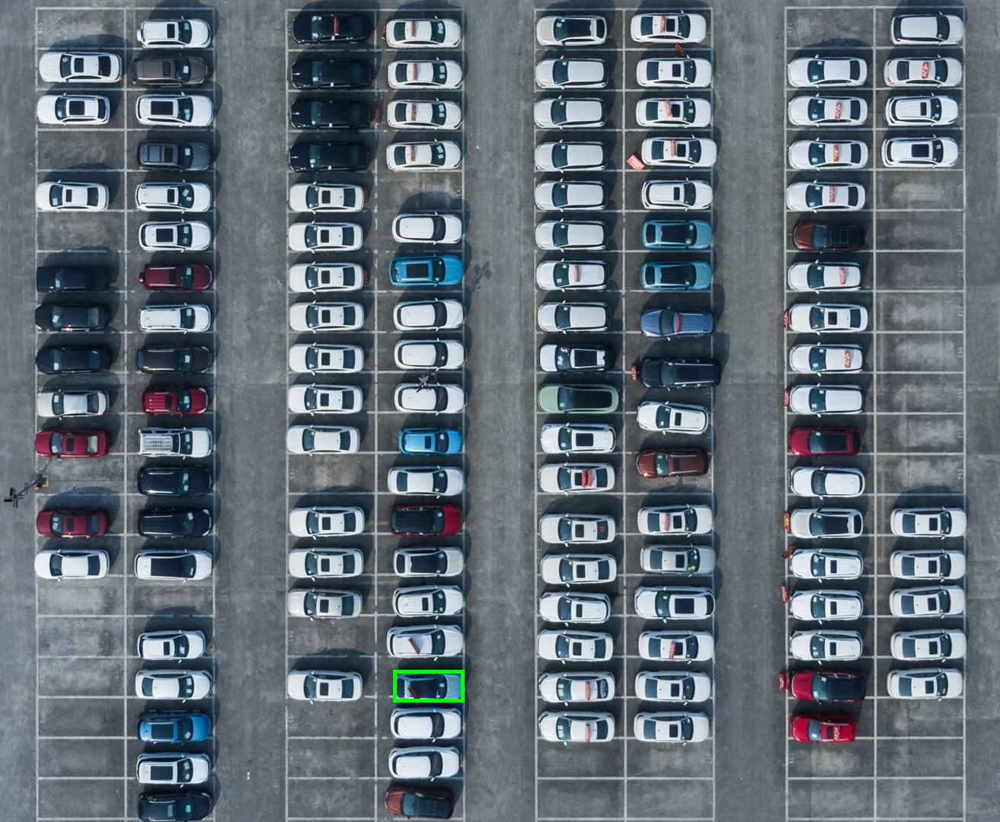

检测框中 y_center 最大的候选框: [516.0, 880.2, 609.2, 922.3]
注意：如果第2题漏检了真正最低的蓝车，本结果仍然可能错误。


In [6]:
# 只对已经检测到的蓝车框做确定性的纵坐标排序。
# 这一步不再调用 VLM，不等于模型自己完成了“寻找全图最低蓝车”。
detected = get_native_boxes(img2, t2_det)
if detected:
    idx = max(range(len(detected)),
              key=lambda i: (detected[i][1]+detected[i][3])/2)
    target = detected[idx]
    from PIL import ImageDraw
    candidate = img2.copy()
    draw = ImageDraw.Draw(candidate)
    draw.rectangle([int(v) for v in target], outline="lime", width=5)
    display(candidate)
    print("检测框中 y_center 最大的候选框:", [round(v,1) for v in target])
    print("注意：如果第2题漏检了真正最低的蓝车，本结果仍然可能错误。")
else:
    print("测试二没有有效检测框，无法进行程序化极值比较。")


## 5. 测试四：多步空间关系定位

原任务：在图2中部偏右找到竖直相邻的两辆亮蓝车，**上面的为 A**；从 A 向图像左侧移动一停车列，再向图像上方移动一停车行，找到 **B**。

诊断顺序：先分别用原生 `referring` 找 A、B；然后使用 `segmentation` 分别请求 A、B 的 Mask。这里 B 的查询仍包含**完整的相对位置变换**，并没有把标准答案或 A 的坐标喂给模型。分别定位只是为了判断错误发生在哪一步；这不同于正式测试的一次性输出 A、B 和关系描述。



========== 04_A_referring | referring ==========


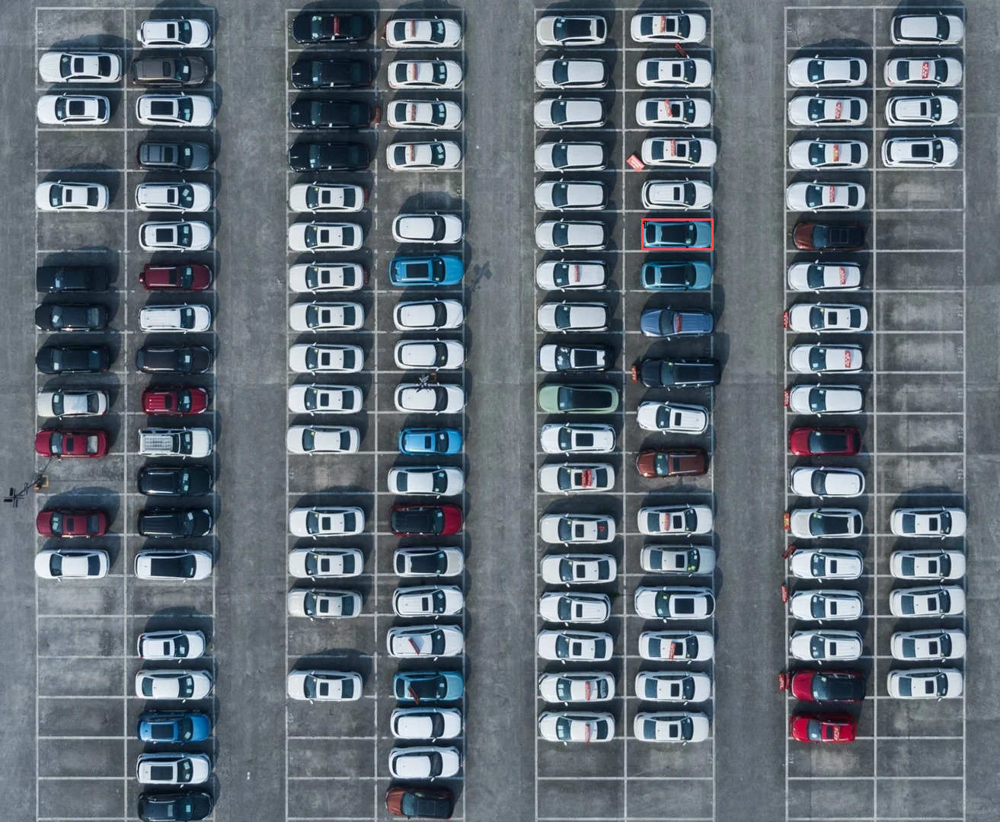

官方原生 query： the UPPER bright blue car of the two bright blue cars parked vertically next to each other in the middle-right area of the image
检测框数： 1 | Mask 数： 0 | 推理耗时： 1.29 s
原始 response：
 <ref>the UPPER bright blue car of the two bright blue cars parked vertically next to each other in the middle-right area of the image</ref><box><641><266><713><304></box>
说明：本轮未产生可解码 Mask；没有把 BBox 假装成 Mask。

========== 04_B_referring | referring ==========


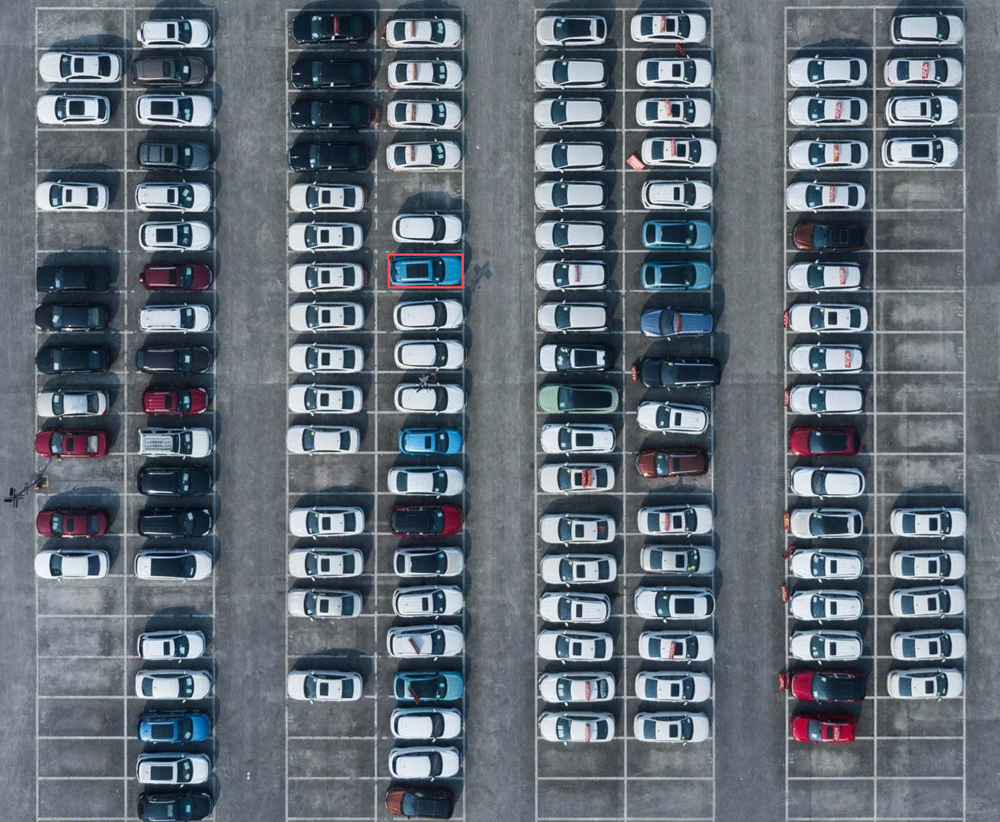

官方原生 query： the car reached by starting from the UPPER bright blue car of the two bright blue cars parked vertically next to each other in the middle-right area of the image, then moving ONE parking-space column toward IMAGE-LEFT and ONE parking-space row toward IMAGE-UP
检测框数： 1 | Mask 数： 0 | 推理耗时： 2.13 s
原始 response：
 <ref>the car reached by starting from the UPPER bright blue car of the two bright blue cars parked vertically next to each other in the middle-right area of the image, then moving ONE parking-space column toward IMAGE-LEFT and ONE parking-space row toward IMAGE-UP</ref><box><388><308><463><350></box>
说明：本轮未产生可解码 Mask；没有把 BBox 假装成 Mask。

========== 04_A_segmentation | segmentation ==========


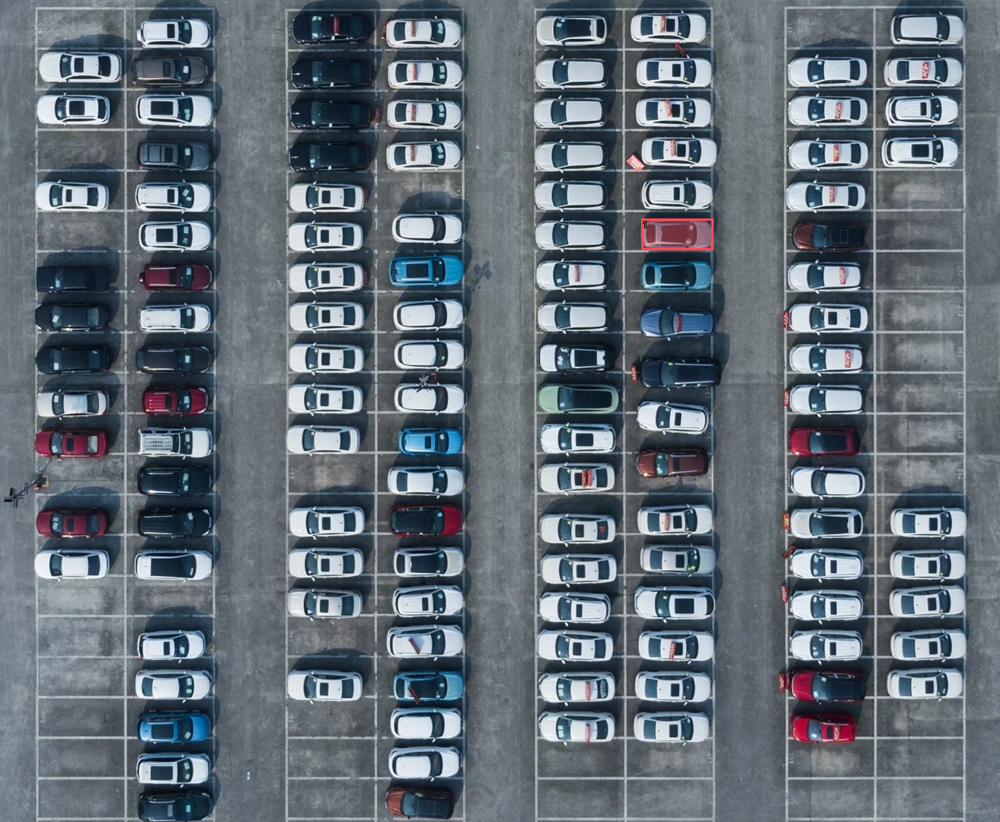

官方原生 query： the UPPER bright blue car of the two bright blue cars parked vertically next to each other in the middle-right area of the image
检测框数： 1 | Mask 数： 1 | 推理耗时： 1.56 s
原始 response：
 <ref>the UPPER bright blue car of the two bright blue cars parked vertically next to each other in the middle-right area of the image</ref><box><641><266><713><304><OBJ></box>

========== 04_B_segmentation | segmentation ==========


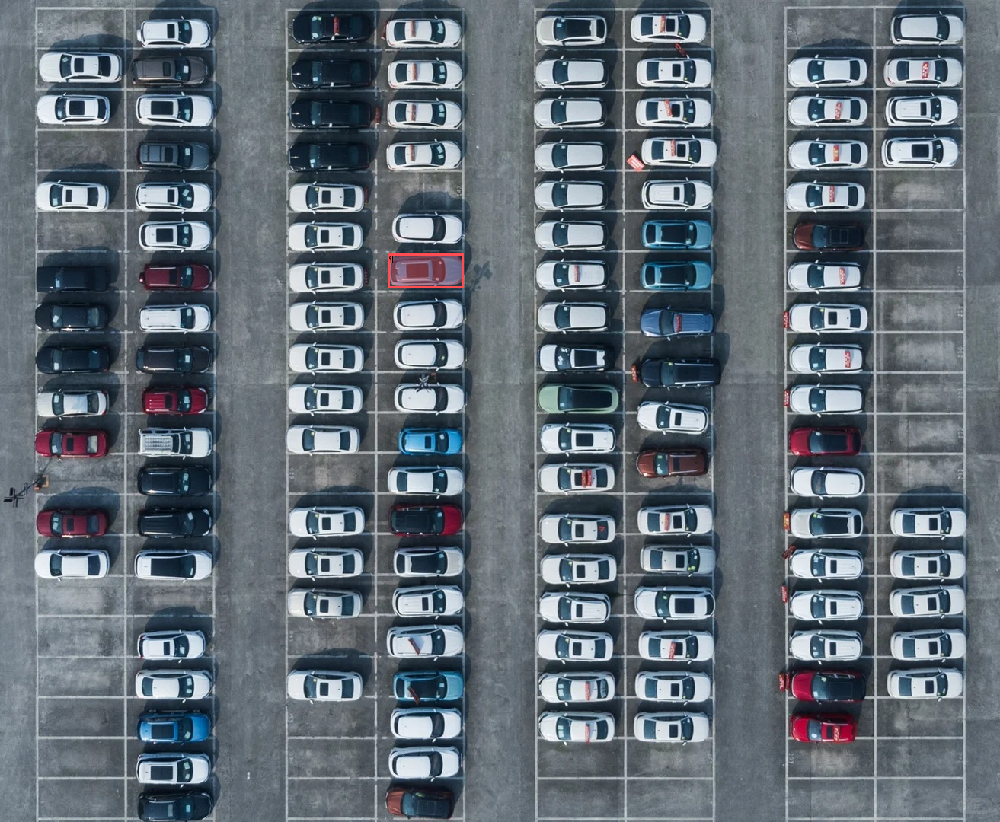

官方原生 query： the car reached by starting from the UPPER bright blue car of the two bright blue cars parked vertically next to each other in the middle-right area of the image, then moving ONE parking-space column toward IMAGE-LEFT and ONE parking-space row toward IMAGE-UP
检测框数： 1 | Mask 数： 1 | 推理耗时： 2.46 s
原始 response：
 <ref>the car reached by starting from the UPPER bright blue car of the two bright blue cars parked vertically next to each other in the middle-right area of the image, then moving ONE parking-space column toward IMAGE-LEFT and ONE parking-space row toward IMAGE-UP</ref><box><388><308><463><350><OBJ></box>


In [7]:
A_QUERY = (
    "the UPPER bright blue car of the two bright blue cars "
    "parked vertically next to each other in the middle-right area of the image"
)
B_QUERY = (
    "the car reached by starting from the UPPER bright blue car "
    "of the two bright blue cars parked vertically next to each other "
    "in the middle-right area of the image, then moving ONE parking-space "
    "column toward IMAGE-LEFT and ONE parking-space row toward IMAGE-UP"
)

t4_a_ref = native_run("04_A_referring", img2, "referring", A_QUERY)
t4_b_ref = native_run("04_B_referring", img2, "referring", B_QUERY)

t4_a_seg = native_run("04_A_segmentation", img2, "segmentation", A_QUERY)
t4_b_seg = native_run("04_B_segmentation", img2, "segmentation", B_QUERY)


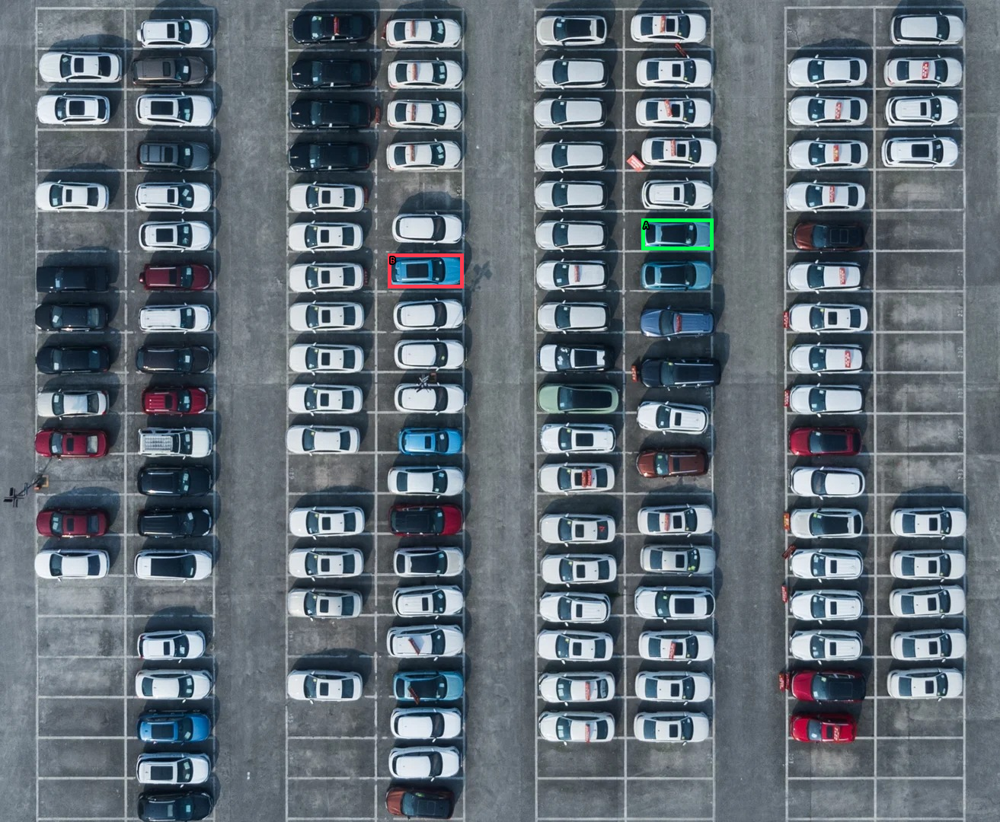

B 的框中心相对 A： 左 下
注意：这是框坐标推导，不代表模型理解或正确执行了停车位位移。


In [8]:
# 将两个 referring 框画在同一张图上，方便检查 A/B 位置关系。
a_boxes = get_native_boxes(img2, t4_a_ref)
b_boxes = get_native_boxes(img2, t4_b_ref)
ab_view = img2.copy()
draw = ImageDraw.Draw(ab_view)
for label, boxes, color in [
    ("A", a_boxes, (0,255,80)),
    ("B", b_boxes, (255,60,80)),
]:
    for i, box in enumerate(boxes):
        x1,y1,x2,y2 = [int(round(v)) for v in box]
        draw.rectangle((x1,y1,x2,y2),outline=color,width=5)
        draw.text((x1+3,y1+3),label if len(boxes)==1 else f"{label}{i+1}",
                  fill=color,stroke_width=2,stroke_fill="black")
display(ab_view)
if len(a_boxes)==1 and len(b_boxes)==1:
    ax = (a_boxes[0][0]+a_boxes[0][2])/2
    ay = (a_boxes[0][1]+a_boxes[0][3])/2
    bx = (b_boxes[0][0]+b_boxes[0][2])/2
    by = (b_boxes[0][1]+b_boxes[0][3])/2
    print("B 的框中心相对 A：",
          "左" if bx<ax else "右" if bx>ax else "水平对齐",
          "上" if by<ay else "下" if by>ay else "竖直对齐")
    print("注意：这是框坐标推导，不代表模型理解或正确执行了停车位位移。")
else:
    print(f"A 框数={len(a_boxes)}，B 框数={len(b_boxes)}；"
          "无法唯一确定两者关系。")
if SAVE_OUTPUTS:
    OUT_DIR.mkdir(parents=True, exist_ok=True)
    ab_view.save(OUT_DIR / "04_AB_comparison.png")


## 6. 总结

总体评价：采用腾讯官方原生任务接口后，模型输出更加规范，BBox 和 Mask 的生成更加稳定，但复杂场景中的全局感知、空间比较和多步推理能力并未出现明显改善。

一、各项测试结果


① 单目标定位	成功	referring 正确定位目标红车，segmentation 成功生成1个 Mask。相比自由提示词测试，大量无关框消失，输出更加精准。

② 多目标定位	部分成功	detection 检出5辆蓝车，segmentation 生成5个 Mask。但仍遗漏多辆明显的蓝车，与此前自由提示词测试的5个有效框基本一致。

③ 空间比较与极值定位	失败	原生 referring 和 segmentation 均选择了错误目标。Python 从已检测的5辆蓝车中排序，也得到同一错误目标，说明前面的漏检足以导致极值选择错误。

④ 多步空间关系推理	失败	正确定位 A，但 B 依然错误。实际输出的 B 位于 A 左下方，而非要求的左上方。虽然 A、B 均成功生成 Mask，但位置变换没有正确完成。

二、值得关注的现象
1. 官方原生接口主要改善的是输出质量，而非空间理解能力。
与之前的自由提示词测试相比，原生接口不再输出大量无关或重复的 BBox，且可以稳定生成对应的 Mask。
但目标漏检、极值选择错误、多步位置变换失败等核心问题依然存在。
2. 全局目标漏检可能是空间比较失败的重要原因。
测试三中，模型直接选择的蓝车与 Python 在测试二的5个检测框中选出的最低蓝车一致。
但图像中还存在位置更低的蓝车，而这些目标没有被测试二完整检测出来。
这说明：即使空间比较规则本身很简单，只要全局感知不完整，最终结果仍可能错误。
不过，该现象还不能证明模型内部一定采用了先检测、再排序的推理过程。
3. 具备准确的目标分割能力，不代表能够正确进行空间推理。
测试四中，模型能够分别生成 A、B 的定位框和 Mask，却仍然无法正确完成“左移一列、上移一行”的操作。
这进一步说明目标级、像素级感知能力与复杂空间关系推理能力之间存在差距。

三、核心结论
1. 原生接口确实有效。 模型定位结果更加集中，Mask 可以正常生成，说明之前的部分输出问题来自任务格式不匹配。
2. 全局感知短板没有得到解决。 原生任务仍只检测到5辆蓝车，漏检问题依然明显。
3. 复杂空间推理能力没有实质改善。 极值比较、多步位置变换等任务依然失败。
4. 模型的优势主要体现在目标定位和像素级分割，而非高层空间关系理解。

四、最终判断

换成官方原生任务后，模型“看得更规范、画得更准确”，但并没有表现出明显更强的空间推理能力。结合此前的 Xiaomi-Lens-0、Qwen3.5-4B 测试，目前可以形成一个值得继续验证的研究判断：

现有小参数 VLM 即使经过专门的视觉定位、分割训练，也不一定能够获得可靠的全局空间理解与多步空间推理能力。

对于后续无人机 VLN 研究，我认为最值得关注的方向是区分并解决三个连续问题：

全局目标感知不完整 → 空间关系理解不准确 → 多步空间推理失败。

这三者之间可能存在误差传递，但目前的测试尚不足以确定各自的因果贡献。

注：本轮仅有两张图片和少量任务，属于定性诊断。原生任务和自由提示词测试的任务格式不同，不宜直接比较准确率。
